In [38]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [40]:
from pathlib import Path
from itertools import islice

pasta = Path('/content/drive/MyDrive/DADOS/Deteccao_Placas')

for arquivo in islice(pasta.iterdir(), 10):
    print(arquivo.name)

annotations.xml
images


In [41]:
pasta_imagens = pasta / 'images'

for arquivo in islice(pasta_imagens.iterdir(), 5):
    print(arquivo.name)

CBD_02DA838CBD4B0000000096_20240531100107700_CAM216036976.jpg
CBD_027468FC45470000000047_20240516100145364_CAM216037582.jpg
CBD_02DA838CBD4B0000000444_20240601100132307_CAM216039061.jpg
CBD_0274681A8D2D0000000054_20240409092303793_CAM216037157.jpg
CBD_0274685FD90C0000006183_20240206094927865_CAM216038649.jpg


Arquivo: CBD_02DA838CBD4B0000000096_20240531100107700_CAM216036976.jpg


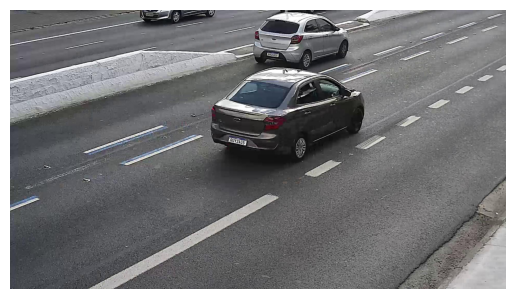

In [7]:
from PIL import Image
import matplotlib.pyplot as plt

arquivo_imagem = next(p for p in pasta_imagens.iterdir() if p.suffix.lower() in ('.jpg', '.jpeg', '.png'))

img = Image.open(arquivo_imagem).convert('RGB')

print('Arquivo:', arquivo_imagem.name)
plt.imshow(img)
plt.axis('off')
plt.show()

In [8]:
import xml.etree.ElementTree as ET

raiz = ET.parse(pasta / 'annotations.xml').getroot()

anotacao = next((item for item in raiz.findall('image') if Path(item.get('name', '')).name == arquivo_imagem.name), None)

print(ET.tostring(anotacao, encoding='unicode') if anotacao is not None else 'Anotação não encontrada.')

<image id="10938" name="CBD_02DA838CBD4B0000000096_20240531100107700_CAM216036976.jpg" width="1920" height="1080">
    <points label="mercosul" source="manual" occluded="0" points="999.45,165.42;996.41,174.25;1036.58,171.21;1034.76,179.12" z_order="0">
    </points>
    <points label="mercosul" source="manual" occluded="0" points="852.06,491.52;849.20,508.63;914.80,502.11;910.32,520.44" z_order="0">
    </points>
    <points label="tradicional" source="manual" occluded="0" points="528.25,12.80;528.05,20.80;552.35,14.70;552.15,22.20" z_order="0">
    </points>
  </image>
  


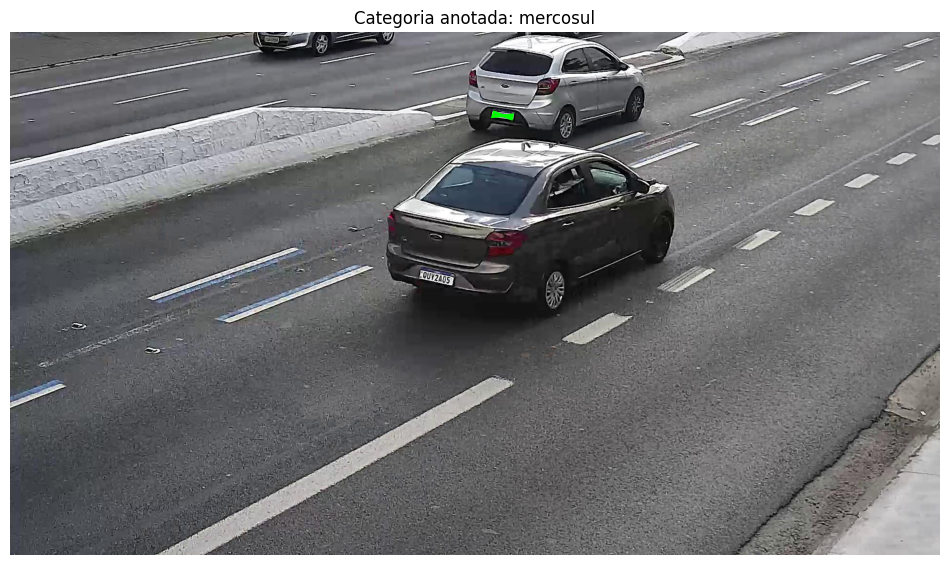

In [9]:
import numpy as np
from matplotlib.patches import Polygon

marca = anotacao.find('points')
pontos = np.array([list(map(float, par.split(','))) for par in marca.get('points').split(';')])

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(img)
ax.add_patch(Polygon(pontos, closed=True, fill=False, edgecolor='lime', linewidth=2))
ax.set_title('Categoria anotada: ' + marca.get('label'))
ax.axis('off')
plt.show()

Tamanho do recorte: (41, 15)


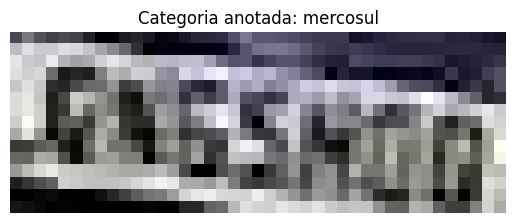

In [10]:
esquerda, topo = np.floor(pontos.min(axis=0)).astype(int)
direita, base = np.ceil(pontos.max(axis=0)).astype(int)

placa = img.crop((esquerda, topo, direita, base))

print('Tamanho do recorte:', placa.size)
plt.imshow(placa)
plt.title('Categoria anotada: ' + marca.get('label'))
plt.axis('off')
plt.show()

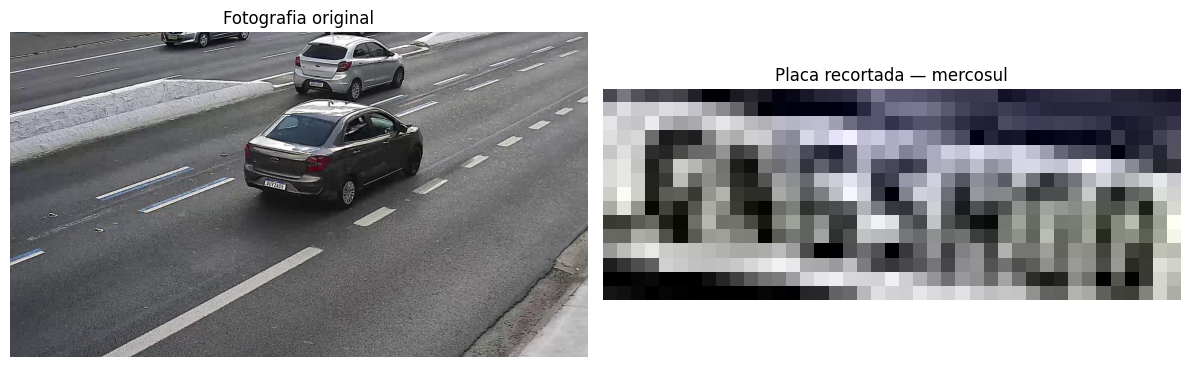

In [11]:
fig, telas = plt.subplots(1, 2, figsize=(12, 5))

telas[0].imshow(img)
telas[0].set_title('Fotografia original')
telas[0].axis('off')

telas[1].imshow(placa)
telas[1].set_title('Placa recortada — ' + marca.get('label'))
telas[1].axis('off')

plt.tight_layout()
plt.show()

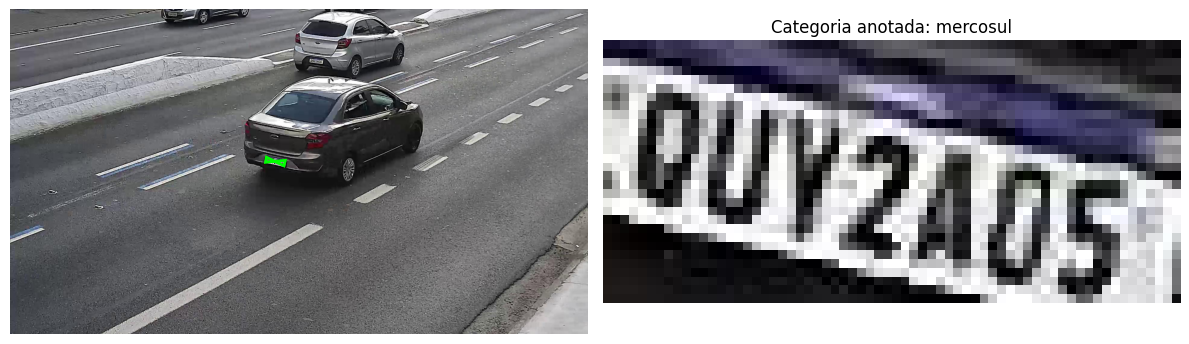

In [12]:
marcas = anotacao.findall('points')
marca = marcas[1]

pontos = np.array([list(map(float, par.split(','))) for par in marca.get('points').split(';')])

esquerda, topo = np.floor(pontos.min(axis=0)).astype(int)
direita, base = np.ceil(pontos.max(axis=0)).astype(int)

placa = img.crop((esquerda, topo, direita, base))

fig, telas = plt.subplots(1, 2, figsize=(12, 5))

telas[0].imshow(img)
telas[0].add_patch(Polygon(pontos, closed=True, fill=False, edgecolor='lime', linewidth=2))
telas[0].axis('off')

telas[1].imshow(placa)
telas[1].set_title('Categoria anotada: ' + marca.get('label'))
telas[1].axis('off')

plt.tight_layout()
plt.show()

In [13]:
from collections import Counter

registros = raiz.findall('image')
categorias = Counter(m.get('label') for r in registros for m in r.findall('points'))

print('Imagens registradas no XML:', len(registros))
print('Marcações de placas:', sum(categorias.values()))
print('Quantidade por categoria:')
print(*categorias.items(), sep='\n')

Imagens registradas no XML: 12000
Marcações de placas: 20233
Quantidade por categoria:
('tradicional', 7332)
('tradicional moto', 788)
('mercosul moto', 2193)
('mercosul', 9918)
('estrangeira', 2)


In [14]:
amostra = [r for r in registros if r.find('points') is not None][:5]

print('Fotografias selecionadas:', len(amostra))
print(*[r.get('name') for r in amostra], sep='\n')

Fotografias selecionadas: 5
CBD_0274680084A20000000047_20240326112052108_CAM216037757.jpg
CBD_0274680084A20000000047_20240328125444798_CAM216038321.jpg
CBD_0274680084A20000000047_20240329134227538_CAM216037599.jpg
CBD_0274680084A20000000047_20240330132454199_CAM216036983.jpg
CBD_0274680084A20000000047_20240401081906723_CAM216037584.jpg


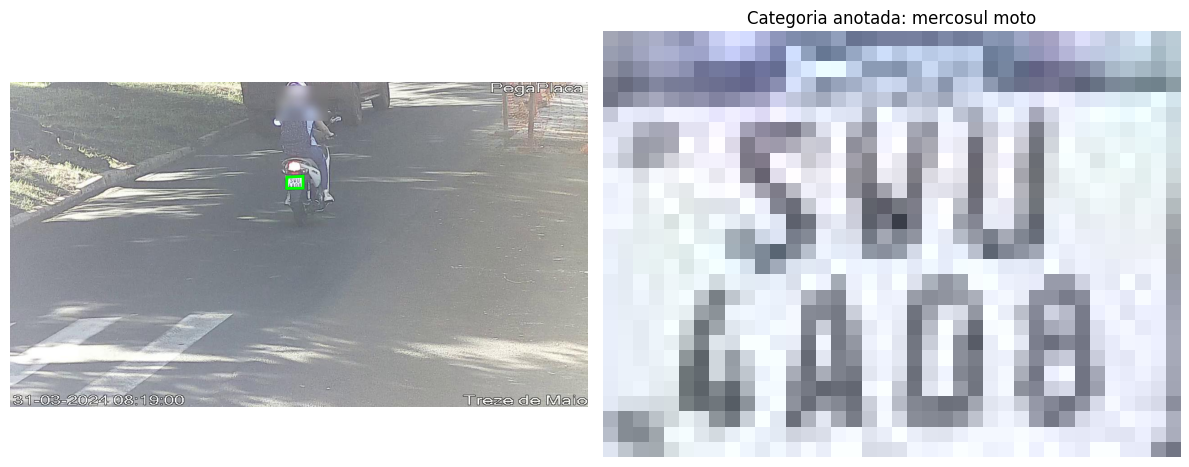

In [15]:
registro_teste = amostra[4]
caminho_teste = pasta_imagens / Path(registro_teste.get('name')).name
foto_teste = Image.open(caminho_teste).convert('RGB')

marca_teste = registro_teste.find('points')
pontos_teste = np.array([list(map(float, par.split(','))) for par in marca_teste.get('points').split(';')])

x1, y1 = np.floor(pontos_teste.min(axis=0)).astype(int)
x2, y2 = np.ceil(pontos_teste.max(axis=0)).astype(int)

recorte_teste = foto_teste.crop((x1, y1, x2, y2))

fig, telas = plt.subplots(1, 2, figsize=(12, 5))
telas[0].imshow(foto_teste)
telas[0].add_patch(Polygon(pontos_teste, closed=True, fill=False, edgecolor='lime', linewidth=2))
telas[0].axis('off')
telas[1].imshow(recorte_teste)
telas[1].set_title('Categoria anotada: ' + marca_teste.get('label'))
telas[1].axis('off')
plt.tight_layout()
plt.show()

In [16]:
import pandas as pd

nomes = [Path(r.get('name')).name for r in amostra]
fotos = [Image.open(pasta_imagens / nome).convert('RGB') for nome in nomes]
marcacoes = [r.find('points') for r in amostra]

coordenadas = [np.array([list(map(float, par.split(','))) for par in m.get('points').split(';')]) for m in marcacoes]
limites = [tuple(np.floor(p.min(axis=0)).astype(int)) + tuple(np.ceil(p.max(axis=0)).astype(int)) for p in coordenadas]
recortes = [foto.crop(limite) for foto, limite in zip(fotos, limites)]

resumo = pd.DataFrame()
resumo['arquivo'] = nomes
resumo['categoria_anotada'] = [m.get('label') for m in marcacoes]
resumo['largura_pixels'] = [recorte.width for recorte in recortes]
resumo['altura_pixels'] = [recorte.height for recorte in recortes]

display(resumo)

,arquivo,categoria_anotada,largura_pixels,altura_pixels
0,CBD_0274680084A20000000047_20240326112052108_C...,tradicional,93,23
1,CBD_0274680084A20000000047_20240328125444798_C...,tradicional moto,47,36
2,CBD_0274680084A20000000047_20240329134227538_C...,mercosul moto,38,24
3,CBD_0274680084A20000000047_20240330132454199_C...,tradicional,49,20
4,CBD_0274680084A20000000047_20240401081906723_C...,mercosul moto,38,28


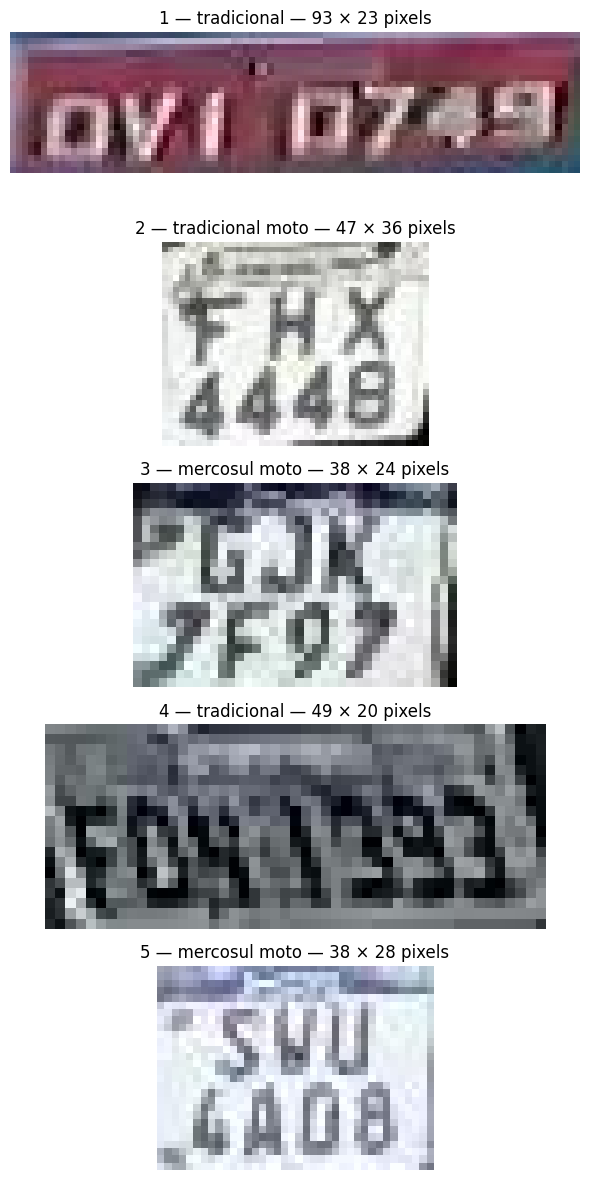

In [17]:
fig, telas = plt.subplots(5, 1, figsize=(6, 12))

_ = [tela.imshow(recorte) for tela, recorte in zip(telas, recortes)]
_ = [tela.set_title(f'{i + 1} — {marca.get("label")} — {recorte.width} × {recorte.height} pixels') for i, (tela, marca, recorte) in enumerate(zip(telas, marcacoes, recortes))]
_ = [tela.axis('off') for tela in telas]

plt.tight_layout()
plt.show()

In [22]:
from pathlib import Path

pasta_resultados = Path('/content/drive/MyDrive/Grupo_C/Resultados_exploracao')
pasta_resultados.mkdir(parents=True, exist_ok=True)

arquivo_resumo = pasta_resultados / 'resumo_5_recortes.csv'
resumo.to_csv(arquivo_resumo, index=False, encoding='utf-8-sig')

print('Tabela salva em:')
print(arquivo_resumo)

Tabela salva em:
/content/drive/MyDrive/Grupo_C/Resultados_exploracao/resumo_5_recortes.csv


In [24]:
pasta_recortes = pasta_resultados / 'recortes_amostra'
pasta_recortes.mkdir(parents=True, exist_ok=True)

arquivos_recortes = [pasta_recortes / f'{i + 1:02d}_{Path(nome).stem}.png' for i, nome in enumerate(nomes)]

for recorte, destino in zip(recortes, arquivos_recortes):
    recorte.save(destino)

print('Recortes salvos:', len(arquivos_recortes))
print('Pasta:', pasta_recortes)

Recortes salvos: 5
Pasta: /content/drive/MyDrive/Grupo_C/Resultados_exploracao/recortes_amostra


In [25]:
import pandas as pd
from PIL import Image

tabela_salva = pd.read_csv(arquivo_resumo)
tamanhos_salvos = [Image.open(caminho).size for caminho in arquivos_recortes]
tamanhos_esperados = list(zip(tabela_salva['largura_pixels'], tabela_salva['altura_pixels']))

print('Linhas na tabela salva:', len(tabela_salva))
print('Imagens abertas:', len(tamanhos_salvos))
print('Dimensões conferem:', tamanhos_salvos == tamanhos_esperados)

Linhas na tabela salva: 5
Imagens abertas: 5
Dimensões conferem: True


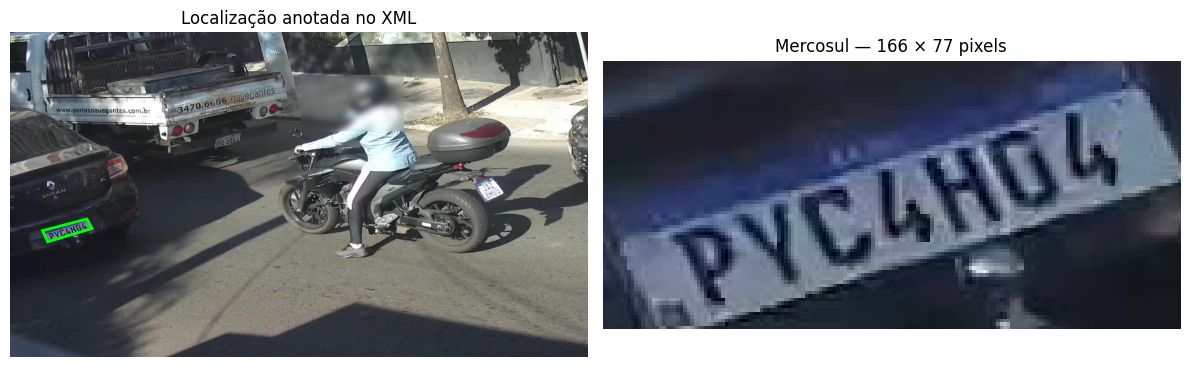

In [26]:
registro_mercosul, marca_mercosul = next((r, m) for r in registros for m in r.findall('points') if m.get('label') == 'mercosul')

caminho_mercosul = pasta_imagens / Path(registro_mercosul.get('name')).name
foto_mercosul = Image.open(caminho_mercosul).convert('RGB')

pontos_mercosul = np.array([list(map(float, par.split(','))) for par in marca_mercosul.get('points').split(';')])
limites_mercosul = tuple(np.floor(pontos_mercosul.min(axis=0)).astype(int)) + tuple(np.ceil(pontos_mercosul.max(axis=0)).astype(int))
recorte_mercosul = foto_mercosul.crop(limites_mercosul)

fig, telas = plt.subplots(1, 2, figsize=(12, 5))
telas[0].imshow(foto_mercosul)
telas[0].add_patch(Polygon(pontos_mercosul, closed=True, fill=False, edgecolor='lime', linewidth=2))
telas[0].set_title('Localização anotada no XML')
telas[0].axis('off')

telas[1].imshow(recorte_mercosul)
telas[1].set_title(f'Mercosul — {recorte_mercosul.width} × {recorte_mercosul.height} pixels')
telas[1].axis('off')

plt.tight_layout()
plt.show()

In [27]:
contagem = pd.Series([m.get('label') for r in registros for m in r.findall('points')]).value_counts()

distribuicao = contagem.rename_axis('categoria').reset_index(name='quantidade')
distribuicao['percentual'] = (distribuicao['quantidade'] / distribuicao['quantidade'].sum() * 100).round(2)

display(distribuicao)

distribuicao.to_csv(pasta_resultados / 'distribuicao_categorias.csv', index=False, encoding='utf-8-sig')

,categoria,quantidade,percentual
0,mercosul,9918,49.02
1,tradicional,7332,36.24
2,mercosul moto,2193,10.84
3,tradicional moto,788,3.89
4,estrangeira,2,0.01


In [29]:
nomes_xml = {Path(r.get('name')).name for r in registros}
nomes_no_drive = {p.name for p in pasta_imagens.iterdir() if p.is_file()}
imagens_ausentes = sorted(nomes_xml - nomes_no_drive)

print('Fotografias registradas no XML:', len(nomes_xml))
print('Fotografias encontradas:', len(nomes_xml & nomes_no_drive))
print('Fotografias ausentes:', len(imagens_ausentes))
print('Primeiros arquivos ausentes:', imagens_ausentes[:5])

Fotografias registradas no XML: 12000
Fotografias encontradas: 11986
Fotografias ausentes: 14
Primeiros arquivos ausentes: ['CBD_0274684465B80000000069_20240429132059170_CAM216037326.jpg', 'CBD_0274686489530000000069_20240513104524274_CAM216037154.jpg', 'CBD_02746865C9F90000005643_20240517145931374_CAM216037897.jpg', 'CBD_027468704D060000000056_20240217125011968_CAM216037887.jpg', 'CBD_0274687EE7210000001530_20240214075646440_CAM216038774.jpg']


In [30]:
lista_ausentes = pd.DataFrame({'arquivo': imagens_ausentes})
lista_ausentes.to_csv(pasta_resultados / 'imagens_nao_localizadas.csv', index=False, encoding='utf-8-sig')

print(lista_ausentes.to_string(index=False))

                                                      arquivo
CBD_0274684465B80000000069_20240429132059170_CAM216037326.jpg
CBD_0274686489530000000069_20240513104524274_CAM216037154.jpg
CBD_02746865C9F90000005643_20240517145931374_CAM216037897.jpg
CBD_027468704D060000000056_20240217125011968_CAM216037887.jpg
CBD_0274687EE7210000001530_20240214075646440_CAM216038774.jpg
CBD_027468852D9F0000000070_20240116124016343_CAM216037414.jpg
CBD_027468875B330000000069_20240507145931173_CAM216039016.jpg
CBD_027468CC42720000000390_20240526133931327_CAM216038928.jpg
CBD_027468F6A28F0000004798_20240201105418875_CAM216038581.jpg
CBD_02DA83322DC50000000058_20240529140121011_CAM216038609.jpg
CBD_02DA837DD03A0000000623_20240528100938453_CAM216038606.jpg
CBD_02DA837DD03A0000002996_20240529093348391_CAM216038768.jpg
CBD_02DA838CBD4B0000000066_20240601103242140_CAM216037943.jpg
CBD_02DA8390B22F0000000201_20240529144417427_CAM216038943.jpg


In [33]:
arquivos_subpastas = {p.name: p for p in pasta_imagens.rglob('*') if p.is_file()}

In [34]:
localizados_subpastas = [nome for nome in imagens_ausentes if nome in arquivos_subpastas]
ainda_nao_localizados = [nome for nome in imagens_ausentes if nome not in arquivos_subpastas]

print('Localizados em subpastas:', len(localizados_subpastas))
print('Ainda não localizados:', len(ainda_nao_localizados))

Localizados em subpastas: 0
Ainda não localizados: 14


In [37]:
registros_disponiveis = [r for r in registros if Path(r.get('name')).name in arquivos_subpastas]

registros_com_placas = [r for r in registros_disponiveis if r.find('points') is not None]

print('Fotografias localizadas:', len(registros_disponiveis))
print('Fotografias localizadas com placas anotadas:', len(registros_com_placas))
print('Total de placas nessas fotografias:', sum(len(r.findall('points')) for r in registros_com_placas))

Fotografias localizadas: 11986
Fotografias localizadas com placas anotadas: 11931
Total de placas nessas fotografias: 20212


In [42]:
placas = pd.DataFrame([{'arquivo': Path(r.get('name')).name, 'categoria': m.get('label'), 'pontos': m.get('points')} for r in registros_com_placas for m in r.findall('points')])

placas['quantidade_pontos'] = placas['pontos'].str.split(';').str.len()

print('Total de placas:', len(placas))
print('Quantidade de pontos por anotação:')
print(placas['quantidade_pontos'].value_counts().sort_index())

display(placas.head())

Total de placas: 20212
Quantidade de pontos por anotação:
quantidade_pontos
1       11
2        4
3       13
4    20086
5       85
6        9
7        1
8        2
9        1
Name: count, dtype: int64


,arquivo,categoria,pontos,quantidade_pontos
0,CBD_0274680084A20000000047_20240326112052108_C...,tradicional,"502.97,366.17;501.88,348.80;593.71,344.68;590....",4
1,CBD_0274680084A20000000047_20240328125444798_C...,tradicional moto,"976.00,371.56;979.49,338.82;934.15,341.33;933....",4
2,CBD_0274680084A20000000047_20240328125444798_C...,tradicional,"476.97,237.90;479.10,216.20;402.96,215.23;403....",4
3,CBD_0274680084A20000000047_20240329134227538_C...,mercosul moto,"1257.48,247.99;1260.19,226.68;1226.87,225.71;1...",4
4,CBD_0274680084A20000000047_20240330132454199_C...,tradicional,"488.21,119.78;481.91,102.20;440.23,105.02;445....",4


In [43]:
pasta_veiculos = pasta.parent / 'Deteccao_Veiculos'

print('Pasta encontrada:', pasta_veiculos.exists())
print('Conteúdo:')
print(*[p.name for p in pasta_veiculos.iterdir()], sep='\n')

Pasta encontrada: True
Conteúdo:
train
labels
data.yaml


In [44]:
placas = pd.DataFrame([{'arquivo': Path(r.get('name')).name, 'categoria': m.get('label'), 'pontos': m.get('points')} for r in registros_com_placas for m in r.findall('points')])

placas['quantidade_pontos'] = placas['pontos'].str.split(';').str.len()

print('Total de placas:', len(placas))
print('Quantidade de pontos por anotação:')
print(placas['quantidade_pontos'].value_counts().sort_index())

display(placas.head())

Total de placas: 20212
Quantidade de pontos por anotação:
quantidade_pontos
1       11
2        4
3       13
4    20086
5       85
6        9
7        1
8        2
9        1
Name: count, dtype: int64


,arquivo,categoria,pontos,quantidade_pontos
0,CBD_0274680084A20000000047_20240326112052108_C...,tradicional,"502.97,366.17;501.88,348.80;593.71,344.68;590....",4
1,CBD_0274680084A20000000047_20240328125444798_C...,tradicional moto,"976.00,371.56;979.49,338.82;934.15,341.33;933....",4
2,CBD_0274680084A20000000047_20240328125444798_C...,tradicional,"476.97,237.90;479.10,216.20;402.96,215.23;403....",4
3,CBD_0274680084A20000000047_20240329134227538_C...,mercosul moto,"1257.48,247.99;1260.19,226.68;1226.87,225.71;1...",4
4,CBD_0274680084A20000000047_20240330132454199_C...,tradicional,"488.21,119.78;481.91,102.20;440.23,105.02;445....",4


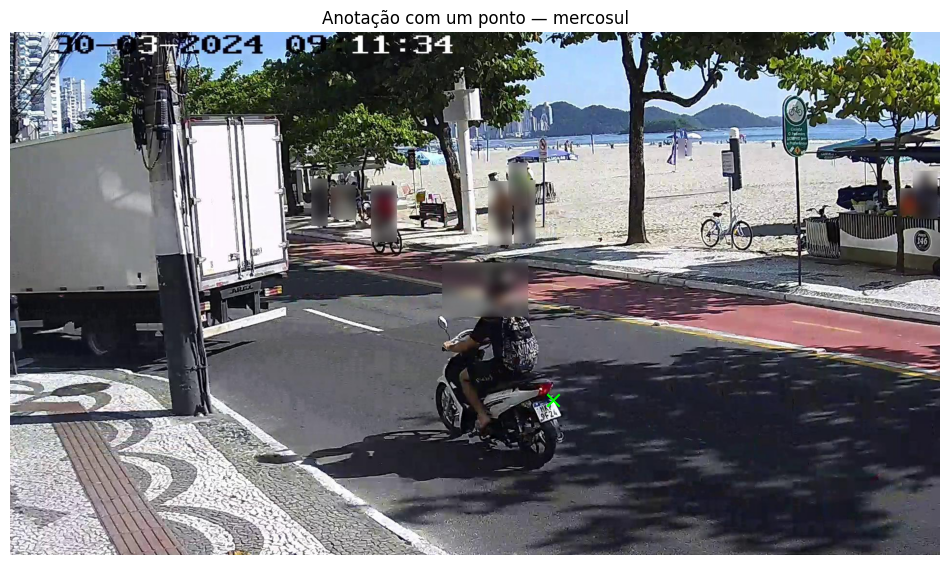

Arquivo: CBD_0274680084A20000006160_20240330091136817_CAM216038593.jpg
Coordenadas: 1120.89,760.07


In [46]:
caso = placas.loc[placas['quantidade_pontos'] == 1].iloc[0]

foto_caso = Image.open(arquivos_subpastas[caso['arquivo']]).convert('RGB')
pontos_caso = np.array([list(map(float, par.split(','))) for par in caso['pontos'].split(';')])

plt.figure(figsize=(12, 7))
plt.imshow(foto_caso)
plt.scatter(pontos_caso[:, 0], pontos_caso[:, 1], color='lime', s=80, marker='x')
plt.title('Anotação com um ponto — ' + caso['categoria'])
plt.axis('off')
plt.show()

print('Arquivo:', caso['arquivo'])
print('Coordenadas:', caso['pontos'])

In [54]:
coordenadas_placas = [np.array([list(map(float, par.split(','))) for par in texto.split(';')]) for texto in placas['pontos']]

placas['largura_anotada'] = [p[:, 0].max() - p[:, 0].min() for p in coordenadas_placas]
placas['altura_anotada'] = [p[:, 1].max() - p[:, 1].min() for p in coordenadas_placas]

placas['tem_area'] = (placas['largura_anotada'] > 0) & (placas['altura_anotada'] > 0)

print('Anotações com largura e altura positivas:', placas['tem_area'].sum())
print('Anotações sem largura ou sem altura:', (~placas['tem_area']).sum())

display(placas.loc[~placas['tem_area'], ['arquivo', 'categoria', 'quantidade_pontos', 'largura_anotada', 'altura_anotada']].head())

Anotações com largura e altura positivas: 20201
Anotações sem largura ou sem altura: 11


,arquivo,categoria,quantidade_pontos,largura_anotada,altura_anotada
60,CBD_0274680084A20000006160_20240330091136817_C...,mercosul,1,0.0,0.0
1012,CBD_027468106A550000000058_20240104122746966_C...,mercosul,1,0.0,0.0
11224,CBD_027468E124070000000056_20231227130008353_C...,mercosul,1,0.0,0.0
11243,CBD_027468E163380000000076_20240409115851385_C...,mercosul,1,0.0,0.0
11267,CBD_027468E2F0010000000047_20231226110345322_C...,tradicional moto,1,0.0,0.0
